# Understanding the Linear Probe

This notebook explains the first supervised model in the project. The model was trained by reusable package code and a clean script, not by notebook cells. This notebook reads the completed, hash verified artifacts and turns them into an inspectable report.

The linear probe uses the same frozen 384 dimensional DINOv2 embeddings as retrieval. Only one small classification layer is trained. Session 1 is training data, Session 2 is validation data, and Session 3 remains sealed.

## Publication and image rights

This is an independent educational fan project and is not affiliated with Nagano, Chiikawa, or their official rights holders.

The photographs displayed in this notebook were taken by Emma Tong and were deliberately selected for publication with this project. © 2026 Emma Tong. All rights reserved. The original HEIC files and standalone prepared dataset remain outside Git.

## 1. What changed from retrieval?

Nearest image retrieval stores reference embeddings and asks which stored photograph is closest. The linear probe instead learns seven decision functions from labeled Session 1 embeddings.

```text
prepared photo
      ↓
frozen DINOv2
      ↓
384 dimensional normalized embedding
      ↓
one trained affine layer
      ↓
7 logits
      ↓
softmax probabilities
      ↓
predicted doll identity
```

DINOv2 still has no trainable parameters in this experiment. The head has only `384 × 7 + 7 = 2,695` trainable values.

In [1]:
import json
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image

from usagi_visual_identifier.data.loaders import load_catalog_csv
from usagi_visual_identifier.embeddings import load_embedding_artifact
from usagi_visual_identifier.training import load_linear_probe

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 90


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the project configuration."""
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from inside the project repository.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
PROCESSED_ROOT = PROJECT_ROOT / "data/processed"
PRIVATE_ROOT = PROJECT_ROOT / "data/private"
EMBEDDING_ROOT = ARTIFACT_ROOT / "embeddings/facebook_dinov2-small"
MODEL_ROOT = ARTIFACT_ROOT / "models/linear_probe"

latest = json.loads((MODEL_ROOT / "latest.json").read_text(encoding="utf-8"))
run_root = MODEL_ROOT / latest["run_id"]
metadata = json.loads((run_root / "metadata.json").read_text(encoding="utf-8"))
history = pd.DataFrame(
    json.loads((run_root / "training_history.json").read_text(encoding="utf-8"))[
        "epochs"
    ]
)
report = json.loads((run_root / "validation_report.json").read_text(encoding="utf-8"))
retrieval_comparison = json.loads(
    (
        ARTIFACT_ROOT
        / "evaluations/dinov2_small/aggregation_comparison_train_to_validation.json"
    ).read_text(encoding="utf-8")
)
artifact = load_embedding_artifact(
    artifact_path=EMBEDDING_ROOT / "embeddings.npz",
    metadata_path=EMBEDDING_ROOT / "metadata.json",
)
model, verified_metadata = load_linear_probe(
    checkpoint_path=run_root / "checkpoint.pt",
    metadata_path=run_root / "metadata.json",
)
catalog = load_catalog_csv(path=PRIVATE_ROOT / "catalog.csv")
catalog_names = {item.catalog_id: item.display_name for item in catalog.items}
image_index = {image_id: index for index, image_id in enumerate(artifact.image_ids)}


def image_path(image_id: str) -> Path:
    """Resolve one artifact image to its prepared local JPEG."""
    index = image_index[image_id]
    return PROCESSED_ROOT / artifact.processed_relative_paths[index]


def draw_image(axis, image_id: str, title: str) -> None:
    """Draw one approved photograph without retaining an open file handle."""
    with Image.open(image_path(image_id)) as opened:
        axis.imshow(opened.convert("RGB"))
    axis.set_title(title)
    axis.axis("off")


print(f"Verified run: {metadata['run_id']}")
print(f"Training images: {metadata['train_image_count']}")
print(f"Validation images: {metadata['validation_image_count']}")
print(f"Test split accessed: {metadata['test_split_accessed']}")

Verified run: 582a6d5094cc
Training images: 98
Validation images: 42
Test split accessed: False


## 2. The production style boundary

The training run is reproducible because each responsibility has one owner.

1. `linear_probe.py` defines the model, validation rules, training loop, evaluation, checkpoint loading, and artifact publication.
2. `train_linear_probe.py` reads the explicit configuration and starts one clean run.
3. The VS Code launch stores the default configuration in a visible place.
4. Automated tests use invented embeddings to verify determinism, split protection, and checkpoint integrity.
5. This notebook reads completed outputs. It cannot silently change the trained model by running cells out of order.

This separation keeps the training run repeatable while leaving the results easy to inspect and explain.

In [2]:
configuration_rows = {
    "run ID": metadata["run_id"],
    "encoder": metadata["encoder_model_id"],
    "encoder revision": metadata["encoder_model_revision"],
    "embedding dimension": metadata["embedding_dimension"],
    "trainable parameters": metadata["trainable_parameter_count"],
    "device": metadata["device"],
    "seed": metadata["configuration"]["seed"],
    "batch size": metadata["configuration"]["batch_size"],
    "learning rate": metadata["configuration"]["learning_rate"],
    "weight decay": metadata["configuration"]["weight_decay"],
    "maximum epochs": metadata["configuration"]["epochs"],
    "completed epochs": metadata["completed_epochs"],
    "selected epoch": metadata["selected_epoch"],
    "training time in seconds": round(metadata["training_seconds"], 3),
    "selection metric": metadata["selection_metric"],
    "test split accessed": metadata["test_split_accessed"],
}
display(pd.DataFrame({"value": configuration_rows}))

,value
run ID,582a6d5094cc
encoder,facebook/dinov2-small
encoder revision,ed25f3a31f01632728cabb09d1542f84ab7b0056
embedding dimension,384
trainable parameters,2695
device,cpu
seed,42
batch size,16
learning rate,0.01
weight decay,0.0001


## 3. Data and label mapping

The class mapping is derived from sorted stable catalog IDs. It does not depend on row order in a CSV or on the order in which files happen to be read.

Session 1 has 14 training examples per identity. Session 2 has 6 validation examples per identity. This balance means ordinary accuracy and macro recall have the same overall value, but both are still recorded.

split,train,validation
Matcha ice cream,14,6
Airport,14,6
Bakery,14,6
Magical,14,6
Pompompurin,14,6
Chiikawa Park fluffy,14,6
Lobster claws,14,6


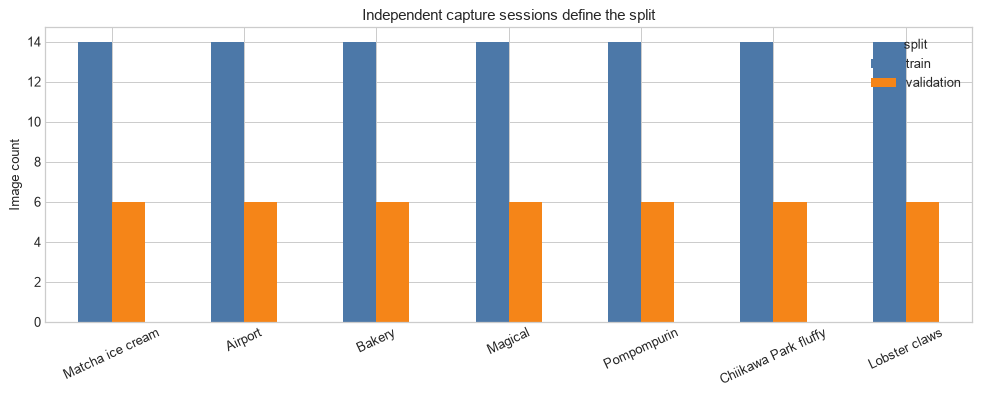

,class index,catalog ID,display name
0,0,usagi-0001,Matcha ice cream
1,1,usagi-0002,Airport
2,2,usagi-0003,Bakery
3,3,usagi-0004,Magical
4,4,usagi-0005,Pompompurin
5,5,usagi-0006,Chiikawa Park fluffy
6,6,usagi-0007,Lobster claws


In [3]:
split_rows = pd.DataFrame(
    {
        "identity": artifact.identity_ids,
        "split": artifact.splits,
    }
)
split_counts = (
    split_rows.groupby(["identity", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(metadata["class_ids"])
)
split_counts.index = [catalog_names[identity] for identity in split_counts.index]
display(split_counts)

axis = split_counts.plot.bar(figsize=(11, 4.5), color=["#4c78a8", "#f58518"])
axis.set_ylabel("Image count")
axis.set_xlabel("")
axis.set_title("Independent capture sessions define the split")
axis.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        {
            "class index": range(len(metadata["class_ids"])),
            "catalog ID": metadata["class_ids"],
            "display name": [catalog_names[value] for value in metadata["class_ids"]],
        }
    )
)

## 4. What the linear classification head learns

A **head** is the final task specific part attached to a more general model representation. DINOv2 produces the embedding, and this classification head turns that embedding into seven doll scores. It is called a head because it sits at the output end of the network.

The layer is **affine** because it performs a linear transformation and then adds a bias. For one embedding vector $x$, it calculates:

$$z = Wx + b$$

`W` contains one 384 dimensional weight vector for each doll. Every one of the 384 embedding values contributes to every output, so this is also called a fully connected layer. `b` contains one bias for each doll. Strictly speaking, $Wx$ is linear and $Wx + b$ is affine. In machine learning, people still commonly call the whole module a linear layer.

The seven resulting values are called logits. They are unrestricted scores rather than probabilities.

Softmax converts logits into positive values that sum to one:

$$p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Cross entropy penalizes the negative log probability assigned to the true identity:

$$L = -\log(p_{true})$$

The diagram below shows the full path. It draws only a few representative connections so the picture stays readable. In the actual layer, all 384 inputs connect to all 7 logits.

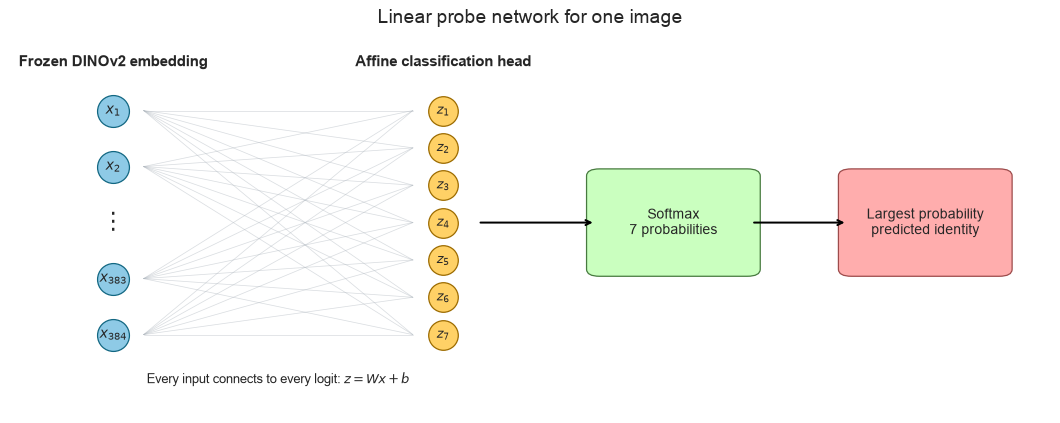

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, axis = plt.subplots(figsize=(12, 4.8))
axis.set_xlim(0, 12)
axis.set_ylim(0, 8)
axis.axis("off")

input_y = [6.5, 5.3, 4.1, 2.9, 1.7]
input_labels = [r"$x_1$", r"$x_2$", r"$\vdots$", r"$x_{383}$", r"$x_{384}$"]
logit_y = np.linspace(6.5, 1.7, 7)

for y_value, label in zip(input_y, input_labels, strict=True):
    if label == r"$\vdots$":
        axis.text(1.2, y_value, label, ha="center", va="center", fontsize=18)
    else:
        axis.scatter(
            1.2, y_value, s=650, color="#8ecae6", edgecolor="#126782", zorder=3
        )
        axis.text(1.2, y_value, label, ha="center", va="center", fontsize=11, zorder=4)

for y_value in logit_y:
    axis.scatter(5.0, y_value, s=560, color="#ffd166", edgecolor="#9c6b00", zorder=3)
for index, y_value in enumerate(logit_y, start=1):
    axis.text(
        5.0, y_value, rf"$z_{index}$", ha="center", va="center", fontsize=10, zorder=4
    )

for input_position in [input_y[0], input_y[1], input_y[-2], input_y[-1]]:
    for output_position in logit_y:
        axis.plot(
            [1.55, 4.65],
            [input_position, output_position],
            color="#adb5bd",
            linewidth=0.6,
            alpha=0.45,
            zorder=1,
        )

softmax_box = FancyBboxPatch(
    (6.8, 3.1),
    1.7,
    2.0,
    boxstyle="round,pad=0.15",
    facecolor="#caffbf",
    edgecolor="#477a3f",
)
prediction_box = FancyBboxPatch(
    (9.7, 3.1),
    1.7,
    2.0,
    boxstyle="round,pad=0.15",
    facecolor="#ffadad",
    edgecolor="#9d4b4b",
)
axis.add_patch(softmax_box)
axis.add_patch(prediction_box)
axis.text(7.65, 4.1, "Softmax\n7 probabilities", ha="center", va="center", fontsize=11)
axis.text(
    10.55,
    4.1,
    "Largest probability\npredicted identity",
    ha="center",
    va="center",
    fontsize=11,
)
axis.annotate(
    "",
    xy=(6.75, 4.1),
    xytext=(5.4, 4.1),
    arrowprops={"arrowstyle": "->", "linewidth": 1.6},
)
axis.annotate(
    "",
    xy=(9.65, 4.1),
    xytext=(8.55, 4.1),
    arrowprops={"arrowstyle": "->", "linewidth": 1.6},
)
axis.text(
    1.2, 7.45, "Frozen DINOv2 embedding", ha="center", fontsize=12, fontweight="bold"
)
axis.text(
    5.0, 7.45, "Affine classification head", ha="center", fontsize=12, fontweight="bold"
)
axis.text(
    3.1,
    0.65,
    r"Every input connects to every logit: $z = Wx + b$",
    ha="center",
    fontsize=10,
)
axis.set_title("Linear probe network for one image", fontsize=15, pad=14)
plt.tight_layout()
plt.show()

Weight shape: (7, 384)
Bias shape: (7,)
Parameter count: 2,695


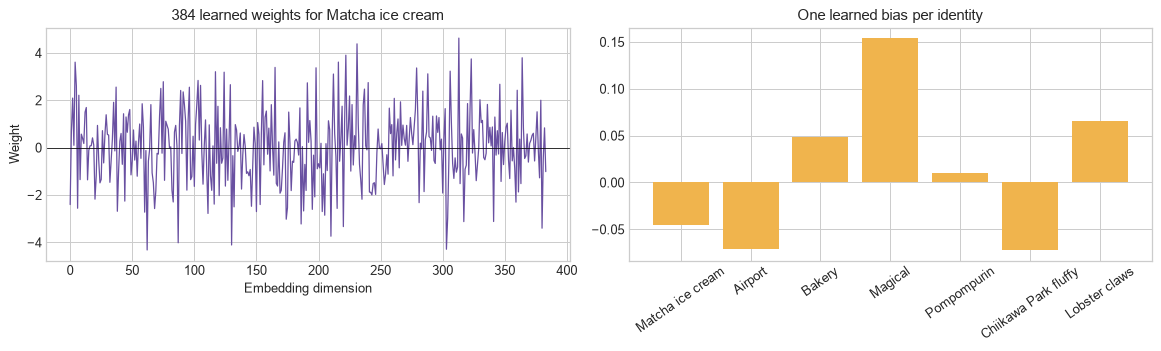

In [5]:
weight = model.classifier.weight.detach().cpu().numpy()
bias = model.classifier.bias.detach().cpu().numpy()

print(f"Weight shape: {weight.shape}")
print(f"Bias shape: {bias.shape}")
print(f"Parameter count: {weight.size + bias.size:,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(weight[0], color="#6950a1", linewidth=1)
axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].set_title(f"384 learned weights for {catalog_names[metadata['class_ids'][0]]}")
axes[0].set_xlabel("Embedding dimension")
axes[0].set_ylabel("Weight")
axes[1].bar(
    [catalog_names[value] for value in metadata["class_ids"]],
    bias,
    color="#f0b44d",
)
axes[1].set_title("One learned bias per identity")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

### What this particular map says

All off diagonal values are between about `-0.26` and `0.00`. The learned class directions are therefore either nearly unrelated or mildly opposed. Magical and Pompompurin are closest to neutral at about `-0.00`, while Airport and Chiikawa Park fluffy are the most opposed at about `-0.26`.

There is no large positive pair suggesting that two class weights point in almost the same direction. The map also does not single out Lobster claws as unusually close to Chiikawa Park fluffy, even though that pair appears in the least decisive prediction. That difference is useful: the Lobster result comes from how one image lands relative to the full classifier, not simply from two class weight vectors being similar. For this project, the low margin image analysis is more actionable than this parameter geometry view.

## 5. One prediction from embedding to loss

The example below uses the validation query with the smallest first versus second probability margin. This is the least decisive correct prediction, so it is more informative than choosing an easy example.

Subtracting the largest logit before exponentiation does not change softmax. It only prevents unnecessarily large exponentials.

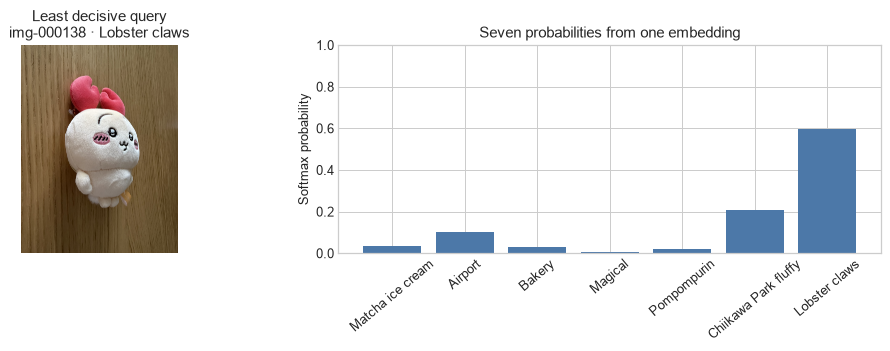

,identity,logit,exp after shift,probability
6,Lobster claws,0.6621,1.0000,0.5972
5,Chiikawa Park fluffy,-0.3919,0.3486,0.2082
1,Airport,-1.0894,0.1735,0.1036
0,Matcha ice cream,-2.2510,0.0543,0.0324
2,Bakery,-2.3677,0.0483,0.0289
4,Pompompurin,-2.6082,0.0380,0.0227
3,Magical,-3.7822,0.0117,0.0070


Probabilities sum to: 1.000000
Cross entropy for the true identity: 0.5155


In [6]:
example = min(report["queries"], key=lambda item: item["probability_margin"])
example_index = image_index[example["image_id"]]
example_embedding = torch.from_numpy(artifact.embeddings[example_index]).unsqueeze(0)
with torch.inference_mode():
    example_logits = model(example_embedding).squeeze(0).numpy(force=True)
stable_exponentials = np.exp(example_logits - example_logits.max())
manual_probabilities = stable_exponentials / stable_exponentials.sum()
true_index = metadata["class_to_index"][example["true_identity"]]
manual_loss = -np.log(manual_probabilities[true_index])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw_image(
    axes[0],
    example["image_id"],
    f"Least decisive query\n{example['image_id']} · {catalog_names[example['true_identity']]}",
)
axes[1].bar(
    [catalog_names[value] for value in metadata["class_ids"]],
    manual_probabilities,
    color="#4c78a8",
)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Softmax probability")
axes[1].set_title("Seven probabilities from one embedding")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

example_table = pd.DataFrame(
    {
        "identity": [catalog_names[value] for value in metadata["class_ids"]],
        "logit": example_logits,
        "exp after shift": stable_exponentials,
        "probability": manual_probabilities,
    }
).sort_values("probability", ascending=False)
display(
    example_table.style.format(
        {"logit": "{:.4f}", "exp after shift": "{:.4f}", "probability": "{:.4f}"}
    )
)
print(f"Probabilities sum to: {manual_probabilities.sum():.6f}")
print(f"Cross entropy for the true identity: {manual_loss:.4f}")

## 6. Optimization and checkpoint selection

Each training batch calculates cross entropy, backpropagates gradients through only the linear head, and lets AdamW update the weights and biases. DINOv2 never participates in backpropagation because its embeddings were computed earlier.

The final epoch is not automatically the selected model. The pipeline keeps the checkpoint with the lowest Session 2 validation loss. This is a simple form of early stopping and protects against keeping later weights that fit Session 1 slightly better while generalizing slightly worse.

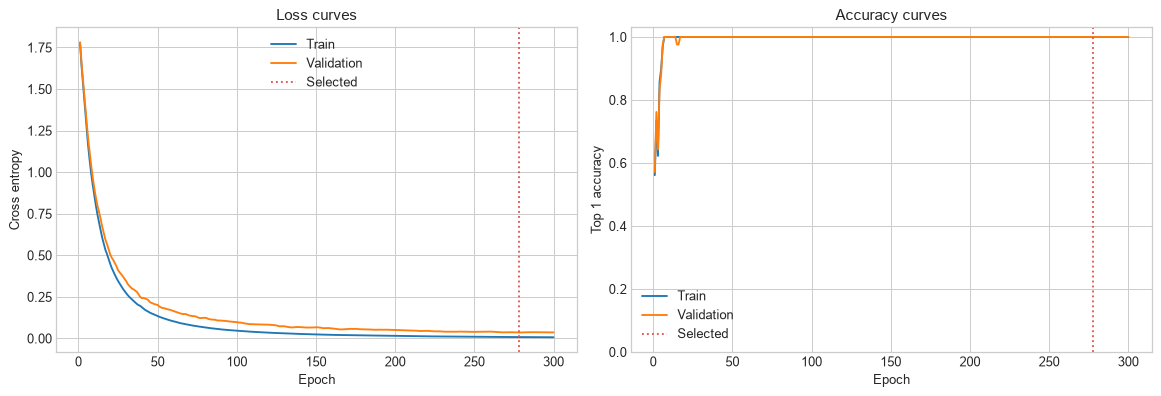

,selected epoch,training loss,validation loss,training Top 1,validation Top 1
0,278,0.0083,0.0356,1.000,1.000


In [7]:
selected_epoch = metadata["selected_epoch"]
selected_row = history.loc[history["epoch"] == selected_epoch].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history["epoch"], history["train_loss"], label="Train")
axes[0].plot(history["epoch"], history["validation_loss"], label="Validation")
axes[0].axvline(selected_epoch, color="#e45756", linestyle=":", label="Selected")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross entropy")
axes[0].set_title("Loss curves")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_top1_accuracy"], label="Train")
axes[1].plot(history["epoch"], history["validation_top1_accuracy"], label="Validation")
axes[1].axvline(selected_epoch, color="#e45756", linestyle=":", label="Selected")
axes[1].set_ylim(0, 1.03)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Top 1 accuracy")
axes[1].set_title("Accuracy curves")
axes[1].legend()
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        {
            "selected epoch": [selected_epoch],
            "training loss": [selected_row["train_loss"]],
            "validation loss": [selected_row["validation_loss"]],
            "training Top 1": [selected_row["train_top1_accuracy"]],
            "validation Top 1": [selected_row["validation_top1_accuracy"]],
        }
    ).style.format(
        {
            "training loss": "{:.4f}",
            "validation loss": "{:.4f}",
            "training Top 1": "{:.3f}",
            "validation Top 1": "{:.3f}",
        }
    )
)

The training loss continues downward after epoch 278, while validation loss rises slightly. Accuracy remains perfect, so loss reveals a smaller change that accuracy cannot show. The later model is becoming more certain on Session 1 without improving any Session 2 decision.

## 7. Linear probe versus nearest image retrieval

Both methods classify every Session 2 query correctly. The linear probe therefore matches the baseline rather than improving it. A tie still teaches us that the frozen representation is linearly separable for these validation photographs.

,Top 1 accuracy,Top 3 accuracy,Macro recall
Nearest image,1.000,1.000,1.000
Linear probe,1.000,1.000,1.000


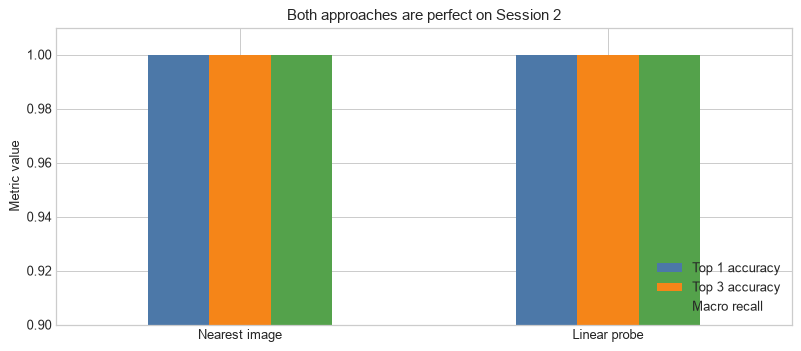

In [8]:
nearest = next(
    item
    for item in retrieval_comparison["reports"]
    if item["aggregation"]["method"] == "nearest_image"
)
comparison = pd.DataFrame(
    {
        "Nearest image": {
            "Top 1 accuracy": nearest["top1_accuracy"],
            "Top 3 accuracy": nearest["top3_accuracy"],
            "Macro recall": nearest["macro_recall"],
        },
        "Linear probe": {
            "Top 1 accuracy": report["top1_accuracy"],
            "Top 3 accuracy": report["top3_accuracy"],
            "Macro recall": report["macro_recall"],
        },
    }
).T
display(comparison.style.format("{:.3f}"))

axis = comparison.plot.bar(figsize=(9, 4), color=["#4c78a8", "#f58518", "#54a24b"])
axis.set_ylim(0.9, 1.01)
axis.set_ylabel("Metric value")
axis.set_xlabel("")
axis.set_title("Both approaches are perfect on Session 2")
axis.tick_params(axis="x", rotation=0)
axis.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Per identity behavior

Aggregate accuracy can hide a weak class. The per identity table and confusion matrix verify that every doll contributes six correct validation predictions.

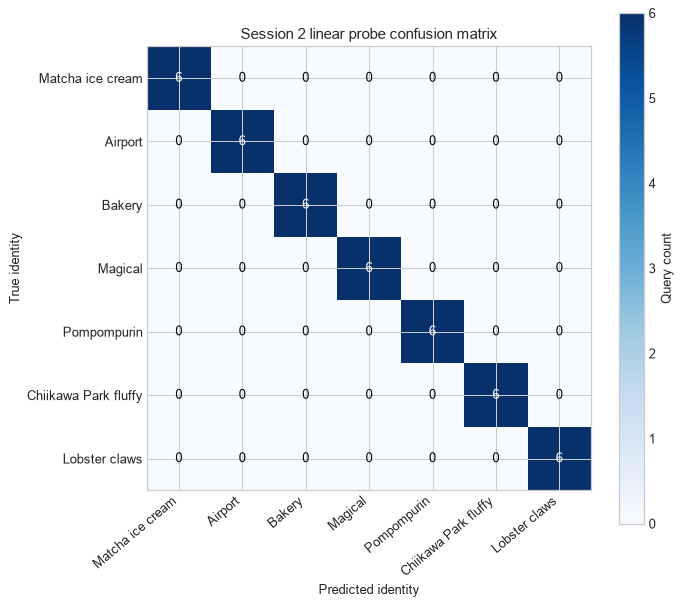

,display name,correct,count,recall
usagi-0001,Matcha ice cream,6.000000,6.000000,1.000
usagi-0002,Airport,6.000000,6.000000,1.000
usagi-0003,Bakery,6.000000,6.000000,1.000
usagi-0004,Magical,6.000000,6.000000,1.000
usagi-0005,Pompompurin,6.000000,6.000000,1.000
usagi-0006,Chiikawa Park fluffy,6.000000,6.000000,1.000
usagi-0007,Lobster claws,6.000000,6.000000,1.000


In [9]:
query_frame = pd.DataFrame(report["queries"])
identity_order = metadata["class_ids"]
confusion = pd.crosstab(
    query_frame["true_identity"], query_frame["predicted_identity"]
).reindex(index=identity_order, columns=identity_order, fill_value=0)

fig, axis = plt.subplots(figsize=(8, 7))
heat = axis.imshow(confusion.to_numpy(), cmap="Blues")
labels = [catalog_names[value] for value in identity_order]
axis.set_xticks(range(len(labels)), labels, rotation=40, ha="right")
axis.set_yticks(range(len(labels)), labels)
axis.set_xlabel("Predicted identity")
axis.set_ylabel("True identity")
axis.set_title("Session 2 linear probe confusion matrix")
for row in range(len(labels)):
    for column in range(len(labels)):
        axis.text(
            column,
            row,
            int(confusion.iloc[row, column]),
            ha="center",
            va="center",
            color="white" if confusion.iloc[row, column] > 3 else "black",
        )
fig.colorbar(heat, ax=axis, label="Query count")
plt.tight_layout()
plt.show()

per_identity = pd.DataFrame(report["per_identity"]).T
per_identity.insert(
    0, "display name", [catalog_names[value] for value in per_identity.index]
)
display(per_identity.style.format({"recall": "{:.3f}"}))

## 9. Confidence and calibration

Softmax probabilities are normalized class scores, not guaranteed real world confidence. A model can be overconfident even when its probabilities look precise.

A reliability diagram groups predictions by stated confidence and compares average confidence with observed accuracy. Expected calibration error summarizes the weighted gaps. With only 42 validation queries and no mistakes, this diagram is diagnostic rather than a reliable calibration claim.

,range,count,average confidence,accuracy
0,"(0.4, 0.6]",1,0.597,1.000
1,"(0.8, 1.0]",41,0.977,1.000


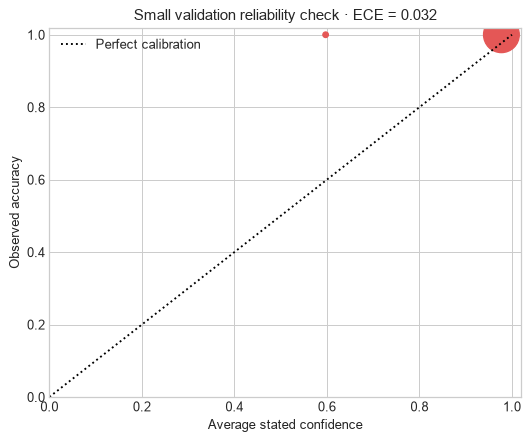

In [10]:
confidence = query_frame["top_probability"].to_numpy()
correct = query_frame["correct"].astype(float).to_numpy()
bin_edges = np.linspace(0, 1, 6)
bin_rows = []
ece = 0.0
for lower, upper in pairwise(bin_edges):
    in_bin = (confidence > lower) & (confidence <= upper)
    if not np.any(in_bin):
        continue
    average_confidence = float(confidence[in_bin].mean())
    accuracy = float(correct[in_bin].mean())
    fraction = float(in_bin.mean())
    ece += fraction * abs(accuracy - average_confidence)
    bin_rows.append(
        {
            "range": f"({lower:.1f}, {upper:.1f}]",
            "count": int(in_bin.sum()),
            "average confidence": average_confidence,
            "accuracy": accuracy,
        }
    )
calibration = pd.DataFrame(bin_rows)
display(
    calibration.style.format({"average confidence": "{:.3f}", "accuracy": "{:.3f}"})
)

fig, axis = plt.subplots(figsize=(6, 5))
axis.plot([0, 1], [0, 1], linestyle=":", color="black", label="Perfect calibration")
axis.scatter(
    calibration["average confidence"],
    calibration["accuracy"],
    s=calibration["count"] * 20,
    color="#e45756",
)
axis.set_xlim(0, 1.02)
axis.set_ylim(0, 1.02)
axis.set_xlabel("Average stated confidence")
axis.set_ylabel("Observed accuracy")
axis.set_title(f"Small validation reliability check · ECE = {ece:.3f}")
axis.legend()
plt.tight_layout()
plt.show()

## 10. The least decisive correct predictions

There are no incorrect Session 2 predictions. The next best diagnostic is the probability margin between the first and second identities. Smaller margins indicate decisions that are closer to changing.

,image_id,true doll,predicted doll,runner up,top_probability,probability_margin,cross_entropy
39,img-000138,Lobster claws,Lobster claws,Chiikawa Park fluffy,0.5972,0.3891,0.5155
38,img-000137,Lobster claws,Lobster claws,Matcha ice cream,0.8117,0.7227,0.2087
37,img-000136,Lobster claws,Lobster claws,Chiikawa Park fluffy,0.8463,0.7925,0.1669
36,img-000135,Lobster claws,Lobster claws,Matcha ice cream,0.9119,0.8435,0.0923
41,img-000140,Lobster claws,Lobster claws,Bakery,0.9346,0.9066,0.0677
24,img-000123,Pompompurin,Pompompurin,Airport,0.9541,0.9220,0.0469


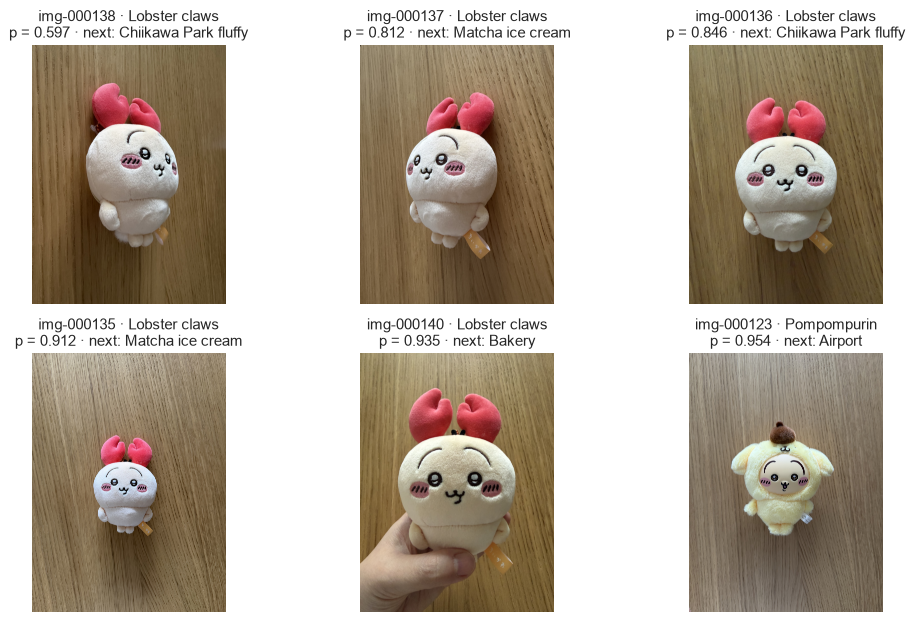

In [11]:
lowest = query_frame.nsmallest(6, "probability_margin").copy()
lowest["true doll"] = lowest["true_identity"].map(catalog_names)
lowest["predicted doll"] = lowest["predicted_identity"].map(catalog_names)
lowest["runner up"] = [
    catalog_names[row["ranked_identities"][1]["identity_id"]]
    for _, row in lowest.iterrows()
]
display(
    lowest[
        [
            "image_id",
            "true doll",
            "predicted doll",
            "runner up",
            "top_probability",
            "probability_margin",
            "cross_entropy",
        ]
    ].style.format(
        {
            "top_probability": "{:.4f}",
            "probability_margin": "{:.4f}",
            "cross_entropy": "{:.4f}",
        }
    )
)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axis, (_, row) in zip(axes.flat, lowest.iterrows(), strict=True):
    runner_up = row["ranked_identities"][1]
    draw_image(
        axis,
        row["image_id"],
        f"{row['image_id']} · {catalog_names[row['true_identity']]}\n"
        f"p = {row['top_probability']:.3f} · next: {catalog_names[runner_up['identity_id']]}",
    )
plt.tight_layout()
plt.show()

Lobster claws provides the three smallest margins. The least decisive photograph is `img-000138`, which gives Lobster probability `0.597` and Chiikawa Park fluffy probability `0.208`. Retrieval also found this exact query difficult. Agreement between two different decision rules makes the side view a credible weakness to investigate later.

## 11. Geometry of the learned class weights

Each row of the weight matrix is a learned direction in the same 384 dimensional space as the image embeddings. The cosine map below compares those seven directions. The diagonal is always `1.00` because each weight vector is being compared with itself, so the off diagonal cells are the useful part.

Here is what I look for:

1. **Large positive off diagonal values** mean two identities use similar combinations of embedding features to raise their logits. Those classes may share visual cues, although this alone does not mean the model will confuse them.
2. **Values near zero** mean the learned directions are mostly unrelated.
3. **Negative values** mean the directions oppose each other. Features that raise one class score tend to lower the other class score.
4. **An unusual row or column** can show that one class was learned differently from the rest. This can suggest a class to inspect alongside the confusion matrix and low margin images.

I should not treat this as a confusion matrix. A prediction depends on the image embedding, all seven weight vectors, and all seven biases. The useful question is whether a notable pair in this map also appears among low margin predictions or real mistakes. If it does, the agreement gives me a stronger reason to inspect that pair. If it does not, the weight similarity is only a description of the learned parameters.

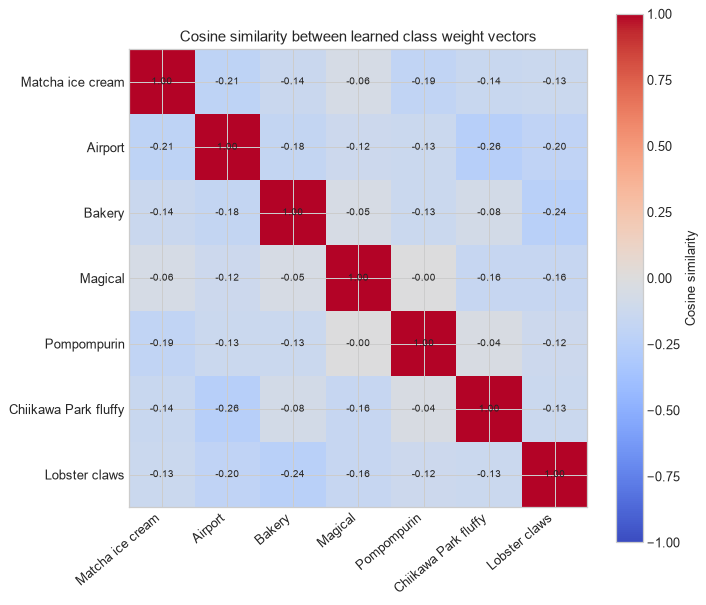

In [12]:
normalized_weight = weight / np.linalg.norm(weight, axis=1, keepdims=True)
weight_cosine = normalized_weight @ normalized_weight.T

fig, axis = plt.subplots(figsize=(8, 7))
heat = axis.imshow(weight_cosine, cmap="coolwarm", vmin=-1, vmax=1)
labels = [catalog_names[value] for value in metadata["class_ids"]]
axis.set_xticks(range(len(labels)), labels, rotation=40, ha="right")
axis.set_yticks(range(len(labels)), labels)
axis.set_title("Cosine similarity between learned class weight vectors")
for row in range(len(labels)):
    for column in range(len(labels)):
        axis.text(
            column,
            row,
            f"{weight_cosine[row, column]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
        )
fig.colorbar(heat, ax=axis, label="Cosine similarity")
plt.tight_layout()
plt.show()

## 12. What makes the run reproducible?

The saved checkpoint alone is not enough. A useful training artifact must answer what data, code level configuration, class order, model revision, device, and selection rule produced it.

The loader verifies the checkpoint hash before creating a model. The run ID is derived from the configuration and embedding provenance. The `latest.json` pointer is written only after the checkpoint, history, validation report, and metadata are complete.

In [13]:
provenance = pd.DataFrame(
    {
        "value": {
            "run ID": verified_metadata["run_id"],
            "dataset fingerprint": verified_metadata["dataset_fingerprint"],
            "embedding artifact hash": verified_metadata["embedding_artifact_sha256"],
            "checkpoint hash": verified_metadata["checkpoint_sha256"],
            "encoder revision": verified_metadata["encoder_model_revision"],
            "Python": verified_metadata["python_version"],
            "PyTorch": verified_metadata["torch_version"],
            "selection metric": verified_metadata["selection_metric"],
            "test split accessed": verified_metadata["test_split_accessed"],
        }
    }
)
display(provenance)

,value
run ID,582a6d5094cc
dataset fingerprint,27c73c3bc69640bb10b36f4846270847dea4fe871cedee...
embedding artifact hash,ddd0145eebc6d2b24fbe0cf66c0e3d3d14957f51a7f2f9...
checkpoint hash,de355a4d78a2313f83f0dc751ff01f879511493bc44952...
encoder revision,ed25f3a31f01632728cabb09d1542f84ab7b0056
Python,3.12.13
PyTorch,2.14.0
selection metric,validation_loss
test split accessed,False


## 13. Decision and next experiment

The linear probe is successful as a supervised learning experiment, but it does not replace nearest image retrieval as the preferred product baseline.

1. Both methods score 42 of 42 on Session 2.
2. Retrieval can add a new doll by adding reference embeddings. The linear probe must expand its output layer and train again.
3. Retrieval shows the exact reference photograph behind a score. A linear class weight is less visually direct.
4. The probe gives logits and probabilities, but those probabilities are not yet calibrated for unknown rejection.

The next modeling experiment can partially tune the final DINOv2 transformer block. Before final Session 3 evaluation, the project also needs unknown validation examples and a frozen rejection rule. Session 3 remains untouched.